In [1]:
%load_ext autoreload
%autoreload 2

# Device selection

In [2]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
# device = "ibm_marrakesh"
device = "ibm_aachen"
# device = "ibm_kingston"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

# Auxiliary lattice plot

72 possible layouts


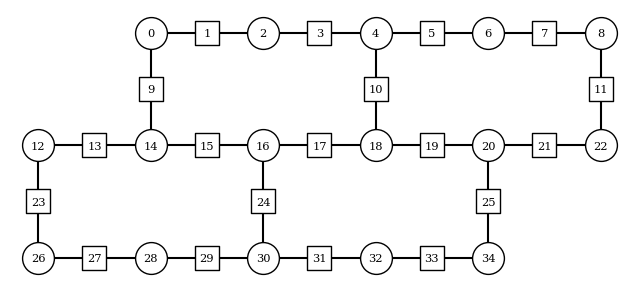

In [3]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 2
plaquette_height = 2

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
nlayouts = len(lattice.get_all_layouts(backend))
print(f"{nlayouts} possible layouts")
lattice.plot_lattice(number_qubits=True)

# Simulation settings

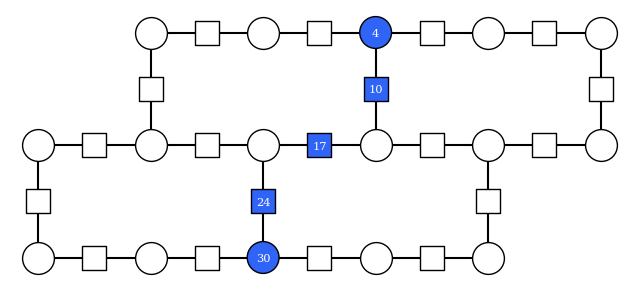

In [4]:
from z2hex.gdd import random, constant, counteract_rotation, zero_mean
from utils.hexec import create_estimator_options
from utils.execrecord import ExecutionRecord
from utils.hexec import ExecDB
from functools import partial

lattice_dims = (plaquette_width, plaquette_height)
J = 2
h = 0.01
lamb = 1

x_basis = True

fractional_gates = False

# string = [27, 26, 34, 43, 52, 60, 59]
string = [4, 10, 17, 24, 30]

final_time = 4
dt = 0.2
steps = 20
desired_error = 1e-2

max_layers = 50
adjust_depth = True

shots = 75000

cal = True
postselect_odr = True
flip_threshold = None
all_or_first_layout_qubit = None
forbidden_qubits = []
max_layouts = 5
recovery = True
# g_func = None
# g_func = partial(counteract_rotation, ham_param=J)
# g_func = partial(constant, angle=np.pi)
# g_func = random
g_func = zero_mean

# if callable(g_func):
#     g_func.__name__ = from_matrix.__name__

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": False,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": "auto",
        "shots_per_randomization": "auto"
    },
    "experimental": {
        "execution_path": "gen3-turbo"
    }
}

# execution_database = "z2_hex_jobs_dec.json" # Last db with good jobs / Not in the new order
execution_database = "z2_hex_jobs.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

execution_record_path = "../../../../Executions_record.xlsx"
execrecord = ExecutionRecord(execution_record_path)

lattice.plot_highlighted_qubits(string, colors=["#2f64f7"]*len(string))

# Error guarantees

In [5]:
from z2hex.geometry import HeavyHexLattice
from z2hex.circs import trotter_dt
import numpy as np

lattice = HeavyHexLattice(*lattice_dims)

error_dt = trotter_dt(desired_error, lattice, J, h, lamb)
nsteps = np.ceil(final_time / error_dt)

print(f"With provided the hardware error Δt should be:\nΔt = {error_dt:.5f}")
print(f"To correctly reach the desired final time, the number of layers required is:\nN = {nsteps} ({nsteps*6} 2Qb depth)")

With provided the hardware error Δt should be:
Δt = 0.04448
To correctly reach the desired final time, the number of layers required is:
N = 90 (540 2Qb depth)


In [6]:
from z2hex.circs import trotter_error

lattice = HeavyHexLattice(*lattice_dims)

settings_error = trotter_error(dt, lattice, J, h, lamb)
sim_max_nlayers = np.ceil(final_time // dt).astype(int)

print(f"With the current simultation settings Δt is at most\nΔt = {dt:.5f}")
print(f"The error per layer commited in the wrost case is\nƐ = {settings_error:.05}")
print(f"The number of layers at the final evolution time is\nN = {sim_max_nlayers} ({6*sim_max_nlayers} 2Qb depth)")

With the current simultation settings Δt is at most
Δt = 0.20000
The error per layer commited in the wrost case is
Ɛ = 0.90920
The number of layers at the final evolution time is
N = 19 (114 2Qb depth)


# Record tools

## Add separator

In [7]:
# execrecord.add_separator()

# Circuit generation & observables

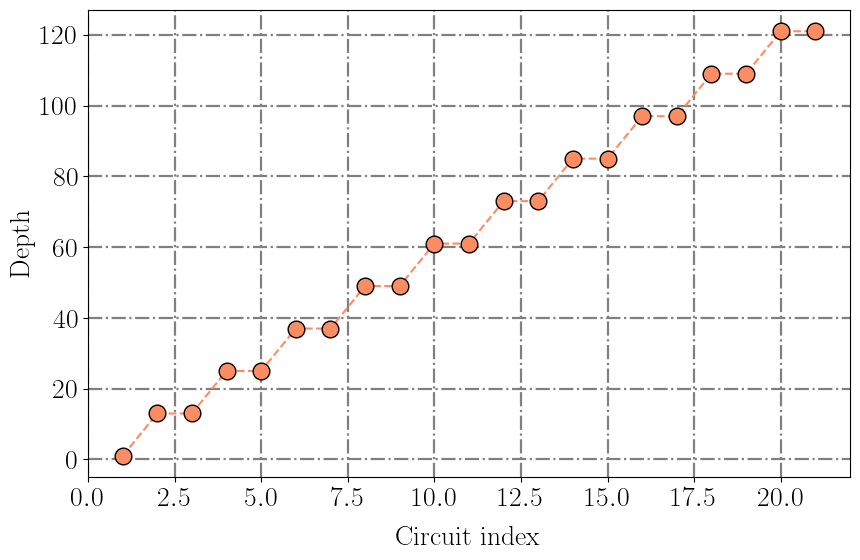

In [ ]:
from z2hex.circs import string_quench_simulation_circuits_dt, simulation_and_odr_circuits, get_layouts
from z2hex.geometry import HeavyHexLattice, sort_layouts_by_func, measurement_decoherence_layout_cost
from z2hex.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.circs import save_many_layout_circs, load_many_layout_circs
from utils.plotting import plot_circuit_arr_depth
import numpy as np

optimization_level = 3

lattice = HeavyHexLattice(*lattice_dims)

if all_or_first_layout_qubit == True:
    all_layouts = np.array(get_layouts(lattice, backend, all_or_first_layout_qubit, forbidden_qubits))
    layouts = sort_layouts_by_func(all_layouts, lambda x: measurement_decoherence_layout_cost(x, backend))[:max_layouts]
elif isinstance(all_or_first_layout_qubit, int):
    layouts = [lattice.initial_qubit_layout(first_qubit=all_or_first_layout_qubit, backend=device)]
else:
    layouts = None
circs_args = (lattice, J, h, lamb, string, final_time, dt, steps, backend, optimization_level, g_func, layouts, x_basis, True, False)
extra_options = {"backend": device, "plaquette_width": lattice_dims[0], "plaquette_height": lattice_dims[1], "J": np.array(J).tolist(), "h": np.array(h).tolist(), "λ":np.array(lamb).tolist(), "g": g_func.__name__ if callable(g_func) else g_func, "string_arr": np.array(string).tolist(), "final_time": final_time, "dt": dt, "steps": steps, "first_qubit": all_or_first_layout_qubit, "x_basis": x_basis} | ({"fractional_gates": True} if fractional_gates else {})
if cal:
    circuits, cal_circuits = simulation_and_odr_circuits(*circs_args)
else:
    circuits = string_quench_simulation_circuits_dt(*circs_args)
observable_generating_funcs = [(lambda nqubits, i=i: local_pauli_z(lattice, i)) for i in range(len(lattice))]
postselection_operators_func = lambda nqubits: postselection_operators(lattice, x_basis=False)

plot_circuit_arr_depth(circuits[0])

In [9]:
# from utils.circs import save_circs

# save_circs("trotter_chain_circs_L_5.qpy", circuits)
# save_circs("trotter_chain_odr_circs_L_5.qpy", odr_circuits)

# Send jobs to hardware

In [10]:
from utils.postselection_multithreaded import execute_postselected_sampler_batch

if cal:
    jobs = execute_postselected_sampler_batch(backend, sampler_options, circuits, observable_generating_funcs, postselects_generating_func=postselection_operators_func, cal_circuits=cal_circuits, extra_options=extra_options, job_db=job_db, diagonal_basis="Z")
else:
    jobs = execute_postselected_sampler_batch(backend, sampler_options, circuits, observable_generating_funcs, postselects_generating_func=postselection_operators_func, extra_options=extra_options, job_db=job_db, diagonal_basis="Z")

execrecord.add_record(J, h, lamb, g_func.__name__ if callable(g_func) else None, final_time, dt, steps, lattice, all_or_first_layout_qubit, device, shots, string, x_basis, cal)
print(f"Sent {len(jobs)} jobs")

Sent 42 jobs
